# Self-Supervised Graph Learning for Recommendation (SGL)

**Paper**: *Self-supervised Graph Learning for Recommendation* (Jiancan Wu, Xiang Wang, Fuli Feng, Xiangnan He, Liang Chen, Jianxun Lian, and Xing Xie, SIGIR 2021)  
**Official Reference**: [wujcan/SGL-Torch](https://github.com/wujcan/SGL-Torch)

This self-contained Google Colab notebook merges the entire **SGL** pipeline into a single file:
1. **Environment & Reproducibility Setup**: Imports, device detection (`CUDA` / `CPU`), and seed fixing.
2. **Dataset Download / Generation & Preprocessing**:
   - Automatically downloads official benchmark datasets (`yelp2018`, `amazon-book`, `ifashion`) from `wujcan/SGL-Torch` or generates a synthetic power-law dataset.
   - Builds the normalized bipartite interaction graph $\tilde{A} = D^{-1/2} A D^{-1/2}$.
   - Implements the three graph structure augmentation operators: **Node Dropout (`ND`)**, **Edge Dropout (`ED`)**, and **Random Walk (`RW`)**.
   - Implements the pairwise BPR sampler $\mathcal{O} = \{(u, i, j) \mid (u, i) \in \mathcal{O}^+, (u, j) \in \mathcal{O}^-\}$.
3. **SGL Model & Multi-Task Loss (`_LightGCN` & `SGLModel`)**:
   - $L$-layer LightGCN propagation and uniform layer readout.
   - Joint optimization of **Pairwise BPR Loss** ($\mathcal{L}_{\text{main}}$), **InfoNCE Contrastive SSL Loss** ($\mathcal{L}_{\text{ssl}}$), and **$L_2$ Regularization** ($\|\Theta\|_2^2$).
4. **All-Ranking Top-$K$ Evaluation & Long-Tail Analysis (`Evaluator`)**:
   - Full-ranking `Precision@K`, `Recall@K`, and `NDCG@K` ($K = 20$) with training interaction masking.
   - Long-tail item popularity group decomposition (`Recall@20` across 10 item degree groups).
5. **End-to-End Training Loop & Visualization**:
   - Trains SGL, tracks early stopping, and plots training curves and long-tail group Recall.

In [1]:
# ==============================================================================
# 1. Environment Setup & Imports (Colab Ready)
# ==============================================================================
import os
import random
import urllib.request
from collections import defaultdict
from dataclasses import dataclass, field
from time import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.sparse as torch_sp


def set_seed(seed: int = 2021) -> None:
    """Fixes random seeds across Python, NumPy, and PyTorch (CPU & CUDA) for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True


DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"PyTorch Version: {torch.__version__} | Running on Device: {DEVICE}")

PyTorch Version: 2.11.0+cu130 | Running on Device: cuda:0


## 2. Data Preprocessing, Graph Augmentation (`ND`, `ED`, `RW`) & BPR Sampler

In **SGL** (Section 3.1 of the paper), we construct a bipartite user-item interaction graph $\mathcal{G} = (\mathcal{V}, \mathcal{E})$ where $\mathcal{V} = \mathcal{U} \cup \mathcal{I}$ and $\mathcal{E} = \mathcal{O}^+$.

At the start of each epoch, two stochastic graph augmentations $s_1(\mathcal{G}), s_2(\mathcal{G}) \sim \mathcal{S}$ are generated with dropout ratio $\rho$ (`ssl_ratio`):
- **Node Dropout (`ND`, Eq. 7)**: Drops each user/item node and its incident edges with probability $\rho$: $s(\mathcal{G}) = (M' \odot \mathcal{V}, \mathcal{E})$.
- **Edge Dropout (`ED`, Eq. 8)**: Drops observed edges with probability $\rho$ and shares the resulting subgraph across all $L$ GCN layers: $s(\mathcal{G}) = (\mathcal{V}, M \odot \mathcal{E})$.
- **Random Walk (`RW`, Eq. 9)**: Applies independent Edge Dropout at each GCN layer $l \in \{1, \dots, L\}$: $s(\mathcal{G}) = (\mathcal{V}, M^{(l)} \odot \mathcal{E})$.

In [2]:
# ==============================================================================
# 2. Data Loading, Preprocessing, Graph Augmentation & Pairwise BPR Sampler
# ==============================================================================

def download_sgl_dataset(data_dir: str, dataset_name: str) -> bool:
    """
    Downloads official benchmark dataset files (<dataset>.train and <dataset>.test)
    directly from https://github.com/wujcan/SGL-Torch if requested in Google Colab.
    Supported official datasets: 'yelp2018', 'amazon-book', 'ifashion'.
    """
    if dataset_name not in ["yelp2018", "amazon-book", "ifashion"]:
        return False

    os.makedirs(data_dir, exist_ok=True)
    base_url = f"https://raw.githubusercontent.com/wujcan/SGL-Torch/master/dataset/{dataset_name}"
    for ext in ["train", "test"]:
        target_path = os.path.join(data_dir, f"{dataset_name}.{ext}")
        if not os.path.exists(target_path):
            url = f"{base_url}/{dataset_name}.{ext}"
            print(f"[Download] Fetching {url} ...")
            try:
                urllib.request.urlretrieve(url, target_path)
            except Exception as e:
                print(f"[Download] Could not fetch {url}: {e}")
                return False
    return True


def generate_synthetic_dataset(
    data_dir: str,
    dataset_name: str = "synthetic",
    num_users: int = 300,
    num_items: int = 500,
    interactions_per_user: int = 25,
    seed: int = 2021,
) -> None:
    """
    Generates a synthetic implicit-feedback dataset with a power-law item popularity
    distribution (reflecting the skewed long-tail distribution described in Section 1)
    and saves `<dataset_name>.train` and `<dataset_name>.test` in SGL-Torch CSV format.
    """
    os.makedirs(data_dir, exist_ok=True)
    rng = np.random.default_rng(seed)

    # Power-law item popularity distribution: few head items, many long-tail items
    item_ranks = np.arange(1, num_items + 1, dtype=np.float64)
    item_probs = item_ranks ** (-0.8)
    item_probs /= item_probs.sum()

    train_pairs, test_pairs = [], []

    for u in range(num_users):
        n_inter = max(5, int(rng.poisson(interactions_per_user)))
        n_inter = min(n_inter, num_items // 2)
        items = rng.choice(num_items, size=n_inter, replace=False, p=item_probs)

        # Split 80% train, 20% test
        n_test = max(1, int(len(items) * 0.2))
        train_items = np.sort(items[:-n_test])
        test_items = np.sort(items[-n_test:])

        for i in train_items:
            train_pairs.append(f"{u},{int(i)}")
        for i in test_items:
            test_pairs.append(f"{u},{int(i)}")

    with open(os.path.join(data_dir, f"{dataset_name}.train"), "w", encoding="utf-8") as f:
        f.write("\n".join(train_pairs) + "\n")

    with open(os.path.join(data_dir, f"{dataset_name}.test"), "w", encoding="utf-8") as f:
        f.write("\n".join(test_pairs) + "\n")


def sp_mat_to_sp_tensor(sp_mat: sp.spmatrix) -> torch.Tensor:
    """
    Converts a SciPy sparse matrix into a coalesced PyTorch sparse COO tensor.
    Directly mirrors `sp_mat_to_sp_tensor` in `SGL-Torch/util/pytorch/func.py`.
    """
    coo = sp_mat.tocoo().astype(np.float32)
    indices = torch.from_numpy(np.asarray([coo.row, coo.col], dtype=np.int64))
    values = torch.from_numpy(coo.data)
    return torch.sparse_coo_tensor(indices, values, coo.shape).coalesce()


class SGLDataset:
    """
    Dataset loader and graph builder for SGL, combining the functionality of
    `data/dataset.py` and `SGL.create_adj_mat` from `SGL-Torch`.
    """

    def __init__(
        self,
        data_dir: str = "./dataset/synthetic",
        dataset_name: str = "synthetic",
        ssl_ratio: float = 0.1,
        device: torch.device = DEVICE,
    ):
        self.data_dir = data_dir
        self.dataset_name = dataset_name
        self.ssl_ratio = ssl_ratio
        self.device = device

        train_path, test_path = self._resolve_data_paths()

        self.train_user_dict = defaultdict(list)
        self.test_user_dict = defaultdict(list)
        self.train_user_set = defaultdict(set)

        self.train_users = []
        self.train_items = []

        self.num_users = 0
        self.num_items = 0

        # Parse training and testing interactions
        self._load_file(train_path, is_train=True)
        self._load_file(test_path, is_train=False)

        self.train_users = np.asarray(self.train_users, dtype=np.int32)
        self.train_items = np.asarray(self.train_items, dtype=np.int32)
        self.num_ratings = len(self.train_users)

        self.train_user_dict = {
            u: np.asarray(items, dtype=np.int32) for u, items in self.train_user_dict.items()
        }
        self.test_user_dict = {
            u: np.asarray(items, dtype=np.int32) for u, items in self.test_user_dict.items()
        }

        # Build the intact normalized adjacency matrix D^{-1/2} A D^{-1/2} for the main task
        adj_matrix = self.create_adj_mat(is_subgraph=False)
        self.norm_adj = sp_mat_to_sp_tensor(adj_matrix).to(self.device)

    def _resolve_data_paths(self) -> tuple[str, str]:
        """Checks for existing `.train`/`.test` or `train.txt`/`test.txt`, downloads, or generates synthetic data."""
        sgl_train = os.path.join(self.data_dir, f"{self.dataset_name}.train")
        sgl_test = os.path.join(self.data_dir, f"{self.dataset_name}.test")
        txt_train = os.path.join(self.data_dir, "train.txt")
        txt_test = os.path.join(self.data_dir, "test.txt")

        if os.path.exists(sgl_train) and os.path.exists(sgl_test):
            return sgl_train, sgl_test
        if os.path.exists(txt_train) and os.path.exists(txt_test):
            return txt_train, txt_test

        # Attempt to download from official SGL-Torch GitHub if dataset_name is an official benchmark
        if download_sgl_dataset(self.data_dir, self.dataset_name):
            return sgl_train, sgl_test

        print(f"[Preprocess] Generating synthetic dataset at '{self.data_dir}'...")
        generate_synthetic_dataset(self.data_dir, self.dataset_name)
        return sgl_train, sgl_test

    def _load_file(self, file_path: str, is_train: bool) -> None:
        """
        Reads interaction data supporting both:
        1. SGL-Torch CSV format (`user_id,item_id` per line)
        2. Adjacency list / whitespace-separated format (`user_id item_1 item_2 ...`)
        """
        with open(file_path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                parts = line.split(",") if "," in line else line.split()
                if len(parts) < 2:
                    continue

                u = int(parts[0])
                items = [int(x) for x in parts[1:]]

                self.num_users = max(self.num_users, u + 1)
                self.num_items = max(self.num_items, max(items) + 1)

                for i in items:
                    if is_train:
                        if i not in self.train_user_set[u]:
                            self.train_user_dict[u].append(i)
                            self.train_user_set[u].add(i)
                            self.train_users.append(u)
                            self.train_items.append(i)
                    else:
                        self.test_user_dict[u].append(i)

    def create_adj_mat(self, is_subgraph: bool = False, aug_type: str = "ed") -> sp.spmatrix:
        """
        Builds and normalizes the bipartite user-item adjacency matrix.
        Directly mirrors `SGL.create_adj_mat` in `SGL-Torch/model/general_recommender/SGL.py`.
        """
        n_nodes = self.num_users + self.num_items
        users_np, items_np = self.train_users, self.train_items
        aug_type = aug_type.lower()

        if is_subgraph and self.ssl_ratio > 0:
            if aug_type == "nd":
                # Node Dropout (ND, Eq. 7): Drop `ssl_ratio` fraction of user and item nodes
                drop_user_size = int(self.num_users * self.ssl_ratio)
                drop_item_size = int(self.num_items * self.ssl_ratio)
                drop_user_idx = np.random.choice(self.num_users, size=drop_user_size, replace=False)
                drop_item_idx = np.random.choice(self.num_items, size=drop_item_size, replace=False)

                indicator_user = np.ones(self.num_users, dtype=np.float32)
                indicator_item = np.ones(self.num_items, dtype=np.float32)
                indicator_user[drop_user_idx] = 0.0
                indicator_item[drop_item_idx] = 0.0

                diag_indicator_user = sp.diags(indicator_user)
                diag_indicator_item = sp.diags(indicator_item)

                R = sp.csr_matrix(
                    (np.ones_like(users_np, dtype=np.float32), (users_np, items_np)),
                    shape=(self.num_users, self.num_items),
                )
                R_prime = diag_indicator_user.dot(R).dot(diag_indicator_item)
                user_np_keep, item_np_keep = R_prime.nonzero()
                ratings_keep = R_prime.data
                tmp_adj = sp.csr_matrix(
                    (ratings_keep, (user_np_keep, item_np_keep + self.num_users)),
                    shape=(n_nodes, n_nodes),
                )
            elif aug_type in ["ed", "rw"]:
                # Edge Dropout (ED, Eq. 8) & Random Walk per-layer (RW, Eq. 9):
                # Retain (1 - ssl_ratio) fraction of observed edges
                keep_size = int(len(users_np) * (1.0 - self.ssl_ratio))
                keep_idx = np.random.choice(len(users_np), size=keep_size, replace=False)
                user_np = np.array(users_np)[keep_idx]
                item_np = np.array(items_np)[keep_idx]
                ratings = np.ones_like(user_np, dtype=np.float32)
                tmp_adj = sp.csr_matrix(
                    (ratings, (user_np, item_np + self.num_users)),
                    shape=(n_nodes, n_nodes),
                )
            else:
                raise ValueError(f"Unsupported aug_type '{aug_type}'. Expected 'nd', 'ed', or 'rw'.")
        else:
            # Intact bipartite interaction graph G = (V, E)
            ratings = np.ones_like(users_np, dtype=np.float32)
            tmp_adj = sp.csr_matrix(
                (ratings, (users_np, items_np + self.num_users)),
                shape=(n_nodes, n_nodes),
            )

        # Symmetrize bipartite adjacency matrix: A = tmp_adj + tmp_adj^T
        adj_mat = tmp_adj + tmp_adj.T

        # Symmetric Laplacian normalization: D^{-1/2} A D^{-1/2}
        rowsum = np.array(adj_mat.sum(1))
        with np.errstate(divide="ignore"):
            d_inv = np.power(rowsum, -0.5).flatten()
        d_inv[np.isinf(d_inv)] = 0.0
        d_mat_inv = sp.diags(d_inv)
        norm_adj_tmp = d_mat_inv.dot(adj_mat)
        adj_matrix = norm_adj_tmp.dot(d_mat_inv)

        return adj_matrix

    def sample_subgraphs(
        self, aug_type: str = "ed", n_layers: int = 3
    ) -> tuple[torch.Tensor | list[torch.Tensor], torch.Tensor | list[torch.Tensor]]:
        """
        Generates two augmented graph views `sub_graph1` and `sub_graph2` per epoch:
        - For 'nd' or 'ed': returns two single sparse adjacency tensors shared across layers.
        - For 'rw': returns two lists of `n_layers` sparse adjacency tensors (one per layer).
        """
        aug_type = aug_type.lower()
        if aug_type in ["nd", "ed"]:
            sub_graph1 = sp_mat_to_sp_tensor(
                self.create_adj_mat(is_subgraph=True, aug_type=aug_type)
            ).to(self.device)
            sub_graph2 = sp_mat_to_sp_tensor(
                self.create_adj_mat(is_subgraph=True, aug_type=aug_type)
            ).to(self.device)
            return sub_graph1, sub_graph2
        elif aug_type == "rw":
            sub_graph1, sub_graph2 = [], []
            for _ in range(n_layers):
                tmp1 = self.create_adj_mat(is_subgraph=True, aug_type="rw")
                sub_graph1.append(sp_mat_to_sp_tensor(tmp1).to(self.device))
                tmp2 = self.create_adj_mat(is_subgraph=True, aug_type="rw")
                sub_graph2.append(sp_mat_to_sp_tensor(tmp2).to(self.device))
            return sub_graph1, sub_graph2
        else:
            raise ValueError(f"Invalid aug_type '{aug_type}'. Choose from ['nd', 'ed', 'rw'].")


class PairwiseSampler:
    """
    Pairwise BPR negative sampler matching `PairwiseSamplerV2` in `SGL-Torch/data/sampler.py`.
    Uniformly samples training triplets (u, i, j) where (u, i) in O^+ and (u, j) in O^-.
    """

    def __init__(self, dataset: SGLDataset, batch_size: int = 2048, shuffle: bool = True):
        self.dataset = dataset
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.user_pos_dict = dataset.train_user_dict
        self.user_pos_set = dataset.train_user_set
        self.num_trainings = dataset.num_ratings
        self.num_items = dataset.num_items
        self.users = list(self.user_pos_dict.keys())

    def __iter__(self):
        sampled_users = np.random.choice(self.users, size=self.num_trainings, replace=True)
        unique_users, user_counts = np.unique(sampled_users, return_counts=True)

        all_users, all_pos_items, all_neg_items = [], [], []

        for u, count in zip(unique_users, user_counts):
            pos_items_u = self.user_pos_dict[u]
            pos_set_u = self.user_pos_set[u]

            pos_sampled = np.random.choice(pos_items_u, size=count, replace=True)
            neg_sampled = np.empty(count, dtype=np.int32)
            for idx in range(count):
                j = np.random.randint(0, self.num_items)
                while j in pos_set_u:
                    j = np.random.randint(0, self.num_items)
                neg_sampled[idx] = j

            all_users.append(np.full(count, u, dtype=np.int32))
            all_pos_items.append(pos_sampled)
            all_neg_items.append(neg_sampled)

        users_arr = np.concatenate(all_users)
        pos_arr = np.concatenate(all_pos_items)
        neg_arr = np.concatenate(all_neg_items)

        if self.shuffle:
            perm = np.random.permutation(self.num_trainings)
            users_arr = users_arr[perm]
            pos_arr = pos_arr[perm]
            neg_arr = neg_arr[perm]

        for start in range(0, self.num_trainings, self.batch_size):
            end = min(start + self.batch_size, self.num_trainings)
            yield users_arr[start:end], pos_arr[start:end], neg_arr[start:end]

## 3. SGL Model Architecture & Multi-Task Loss (`_LightGCN` & `SGLModel`)

SGL uses **LightGCN** as the graph encoder backbone without adding any extra trainable parameters:
1. **LightGCN Propagation & Readout (Eq. 1–3)**:
   $$Z^{(l)} = \tilde{A} Z^{(l-1)}, \quad Z = \frac{1}{L+1} \sum_{l=0}^{L} Z^{(l)}$$
2. **Main Supervised Task — BPR Loss (Eq. 4–5)**:
   $$\mathcal{L}_{\text{main}} = \sum_{(u, i, j) \in \mathcal{O}} -\ln \sigma(\hat{y}_{ui} - \hat{y}_{uj}), \quad \hat{y}_{ui} = z_u^\top z_i$$
3. **Auxiliary Self-Supervised Task — InfoNCE Loss (Eq. 10)**:
   $$\mathcal{L}_{\text{ssl}}^{\text{user}} = \sum_{u \in \mathcal{U}} -\ln \frac{\exp(s(z'_u, z''_u) / \tau)}{\sum_{v \in \mathcal{U}} \exp(s(z'_u, z''_v) / \tau)}, \quad \mathcal{L}_{\text{ssl}} = \mathcal{L}_{\text{ssl}}^{\text{user}} + \mathcal{L}_{\text{ssl}}^{\text{item}}$$
4. **Multi-Task Training Objective (Eq. 11)**:
   $$\mathcal{L} = \mathcal{L}_{\text{main}} + \lambda_1 \mathcal{L}_{\text{ssl}} + \lambda_2 \|\Theta\|_2^2$$

In [3]:
# ==============================================================================
# 3. SGL Model & Multi-Task Loss Functions
# ==============================================================================

def inner_product(a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
    """Row-wise inner product between two embedding tensors (Eq. 4)."""
    return torch.sum(a * b, dim=-1)


def bpr_loss(y_diff: torch.Tensor, reduction: str = "sum") -> torch.Tensor:
    """Pairwise Bayesian Personalized Ranking (BPR) loss (Eq. 5)."""
    loss = -F.logsigmoid(y_diff)
    return torch.sum(loss) if reduction == "sum" else torch.mean(loss)


def l2_loss(*weights: torch.Tensor) -> torch.Tensor:
    """Half L2-norm squared regularization loss over 0-th layer ego embeddings."""
    loss = 0.0
    for w in weights:
        loss = loss + torch.sum(torch.pow(w, 2))
    return 0.5 * loss


class _LightGCN(nn.Module):
    """
    LightGCN encoder module equipped with SGL dual-subgraph contrastive forward pass.
    Directly mirrors `_LightGCN` in `SGL-Torch/model/general_recommender/SGL.py`.
    """

    def __init__(
        self,
        num_users: int,
        num_items: int,
        embed_dim: int,
        norm_adj: torch.Tensor,
        n_layers: int = 3,
    ):
        super().__init__()
        self.num_users = num_users
        self.num_items = num_items
        self.embed_dim = embed_dim
        self.norm_adj = norm_adj
        self.n_layers = n_layers

        # Trainable 0-th layer ID embeddings Z^{(0)}
        self.user_embeddings = nn.Embedding(self.num_users, self.embed_dim)
        self.item_embeddings = nn.Embedding(self.num_items, self.embed_dim)

        # Cached final representations used during evaluation
        self._user_embeddings_final = None
        self._item_embeddings_final = None

        self.reset_parameters(init_method="xavier_uniform")

    def reset_parameters(self, init_method: str = "xavier_uniform") -> None:
        """Initializes ego user and item embeddings using Xavier uniform initialization."""
        if init_method == "xavier_uniform":
            nn.init.xavier_uniform_(self.user_embeddings.weight)
            nn.init.xavier_uniform_(self.item_embeddings.weight)
        elif init_method == "xavier_normal":
            nn.init.xavier_normal_(self.user_embeddings.weight)
            nn.init.xavier_normal_(self.item_embeddings.weight)
        else:
            nn.init.uniform_(self.user_embeddings.weight, a=-0.01, b=0.01)
            nn.init.uniform_(self.item_embeddings.weight, a=-0.01, b=0.01)

    def _forward_gcn(
        self, norm_adj: torch.Tensor | list[torch.Tensor]
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """
        Propagates user and item embeddings over L LightGCN layers (Eq. 1-3):
            Z^{(k)} = A_hat * Z^{(k-1)}
            Z = (1 / (L + 1)) * sum_{k=0}^{L} Z^{(k)}
        """
        ego_embeddings = torch.cat(
            [self.user_embeddings.weight, self.item_embeddings.weight], dim=0
        )
        all_embeddings = [ego_embeddings]

        for k in range(self.n_layers):
            if isinstance(norm_adj, list):
                # Random Walk (RW): layer k uses its own independent subgraph norm_adj[k]
                ego_embeddings = torch_sp.mm(norm_adj[k], ego_embeddings)
            else:
                # Main graph, Node Dropout (ND), or Edge Dropout (ED): shared adjacency matrix
                ego_embeddings = torch_sp.mm(norm_adj, ego_embeddings)
            all_embeddings.append(ego_embeddings)

        # Readout function (Eq. 3): uniform mean across layers 0..L
        all_embeddings = torch.stack(all_embeddings, dim=1).mean(dim=1)
        user_embeddings, item_embeddings = torch.split(
            all_embeddings, [self.num_users, self.num_items], dim=0
        )
        return user_embeddings, item_embeddings

    def forward(
        self,
        sub_graph1: torch.Tensor | list[torch.Tensor],
        sub_graph2: torch.Tensor | list[torch.Tensor],
        users: torch.Tensor,
        items: torch.Tensor,
        neg_items: torch.Tensor,
    ) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """
        Computes the forward pass for both the main supervised recommendation task and
        the auxiliary self-supervised contrastive learning task.
        """
        # 1. Graph propagation on intact graph G and augmented views s_1(G), s_2(G)
        user_embeddings, item_embeddings = self._forward_gcn(self.norm_adj)
        user_embeddings1, item_embeddings1 = self._forward_gcn(sub_graph1)
        user_embeddings2, item_embeddings2 = self._forward_gcn(sub_graph2)

        # 2. L2-normalize augmented views so inner product equals cosine similarity s(., .)
        user_embeddings1 = F.normalize(user_embeddings1, dim=1)
        item_embeddings1 = F.normalize(item_embeddings1, dim=1)
        user_embeddings2 = F.normalize(user_embeddings2, dim=1)
        item_embeddings2 = F.normalize(item_embeddings2, dim=1)

        # 3. Look up mini-batch embeddings
        user_embs = F.embedding(users, user_embeddings)
        item_embs = F.embedding(items, item_embeddings)
        neg_item_embs = F.embedding(neg_items, item_embeddings)

        user_embs1 = F.embedding(users, user_embeddings1)
        item_embs1 = F.embedding(items, item_embeddings1)
        user_embs2 = F.embedding(users, user_embeddings2)
        item_embs2 = F.embedding(items, item_embeddings2)

        # 4. Main supervised BPR logits: y_hat_{ui} - y_hat_{uj}
        sup_pos_ratings = inner_product(user_embs, item_embs)      # [batch_size]
        sup_neg_ratings = inner_product(user_embs, neg_item_embs)  # [batch_size]
        sup_logits = sup_pos_ratings - sup_neg_ratings             # [batch_size]

        # 5. Self-supervised InfoNCE logits (Eq. 10)
        pos_ratings_user = inner_product(user_embs1, user_embs2)   # [batch_size]
        pos_ratings_item = inner_product(item_embs1, item_embs2)   # [batch_size]

        tot_ratings_user = torch.matmul(
            user_embs1, torch.transpose(user_embeddings2, 0, 1)
        )  # [batch_size, num_users]
        tot_ratings_item = torch.matmul(
            item_embs1, torch.transpose(item_embeddings2, 0, 1)
        )  # [batch_size, num_items]

        ssl_logits_user = tot_ratings_user - pos_ratings_user[:, None]  # [batch_size, num_users]
        ssl_logits_item = tot_ratings_item - pos_ratings_item[:, None]  # [batch_size, num_items]

        return sup_logits, ssl_logits_user, ssl_logits_item

    def eval(self):
        super().eval()
        with torch.no_grad():
            self._user_embeddings_final, self._item_embeddings_final = self._forward_gcn(
                self.norm_adj
            )
        return self

    @torch.no_grad()
    def predict(self, users: torch.Tensor) -> torch.Tensor:
        if self._user_embeddings_final is None or self._item_embeddings_final is None:
            self._user_embeddings_final, self._item_embeddings_final = self._forward_gcn(
                self.norm_adj
            )
        user_embs = F.embedding(users, self._user_embeddings_final)
        return torch.matmul(user_embs, self._item_embeddings_final.T)


class SGLModel(nn.Module):
    """
    High-level SGL wrapper combining `_LightGCN` with the joint multi-task loss computation.
    """

    def __init__(
        self,
        num_users: int,
        num_items: int,
        norm_adj: torch.Tensor,
        embed_dim: int = 64,
        n_layers: int = 3,
        ssl_temp: float = 0.2,
        ssl_reg: float = 0.1,
        reg: float = 1e-4,
        ssl_mode: str = "both_side",
        param_init: str = "xavier_uniform",
    ):
        super().__init__()
        self.num_users = num_users
        self.num_items = num_items
        self.embed_dim = embed_dim
        self.n_layers = n_layers
        self.ssl_temp = ssl_temp
        self.ssl_reg = ssl_reg
        self.reg = reg
        self.ssl_mode = ssl_mode.lower()

        self.lightgcn = _LightGCN(
            num_users=num_users,
            num_items=num_items,
            embed_dim=embed_dim,
            norm_adj=norm_adj,
            n_layers=n_layers,
        )
        self.lightgcn.reset_parameters(init_method=param_init)

    def calculate_loss(
        self,
        sub_graph1: torch.Tensor | list[torch.Tensor],
        sub_graph2: torch.Tensor | list[torch.Tensor],
        bat_users: torch.Tensor,
        bat_pos_items: torch.Tensor,
        bat_neg_items: torch.Tensor,
    ) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
        """
        Computes the multi-task SGL training loss for a mini-batch (Eq. 11):
            loss = bpr_loss + ssl_reg * infonce_loss + reg * reg_loss
        """
        sup_logits, ssl_logits_user, ssl_logits_item = self.lightgcn(
            sub_graph1, sub_graph2, bat_users, bat_pos_items, bat_neg_items
        )

        # 1. Supervised BPR Loss (Eq. 5)
        batch_bpr_loss = bpr_loss(sup_logits, reduction="sum")

        # 2. L2 Regularization Loss on 0-th layer ego embeddings (Eq. 11)
        batch_reg_loss = l2_loss(
            self.lightgcn.user_embeddings(bat_users),
            self.lightgcn.item_embeddings(bat_pos_items),
            self.lightgcn.item_embeddings(bat_neg_items),
        )

        # 3. InfoNCE Contrastive Self-Supervised Loss (Eq. 10)
        clogits_user = torch.logsumexp(ssl_logits_user / self.ssl_temp, dim=1)
        clogits_item = torch.logsumexp(ssl_logits_item / self.ssl_temp, dim=1)

        if self.ssl_mode == "user_side":
            infonce_loss = torch.sum(clogits_user)
        elif self.ssl_mode == "item_side":
            infonce_loss = torch.sum(clogits_item)
        else:
            infonce_loss = torch.sum(clogits_user + clogits_item)

        weighted_ssl_loss = self.ssl_reg * infonce_loss
        weighted_reg_loss = self.reg * batch_reg_loss
        total_loss = batch_bpr_loss + weighted_ssl_loss + weighted_reg_loss

        return total_loss, batch_bpr_loss, weighted_ssl_loss, weighted_reg_loss

    def eval(self):
        self.lightgcn.eval()
        return super().eval()

    @torch.no_grad()
    def predict(self, users: np.ndarray | list[int] | torch.Tensor) -> np.ndarray:
        if not isinstance(users, torch.Tensor):
            device = self.lightgcn.user_embeddings.weight.device
            users = torch.from_numpy(np.asarray(users)).long().to(device)
        return self.lightgcn.predict(users).cpu().detach().numpy()

## 4. All-Ranking Evaluation Protocol & Long-Tail Group Analysis (`Evaluator`)

Following Section 4.1 of the paper and `reckit/evaluator.py` in `SGL-Torch`:
- For each user $u$ in the test set, we compute preference scores $\hat{y}_{ui} = z_u^\top z_i$ over **all** items $i \in \mathcal{I}$, mask out observed training items with $-\infty$, and evaluate top-$K$ ($K=20$) ranking performance via:
  $$\text{Precision@}K(u) = \frac{|\mathcal{L}_{\text{rec}}^u \cap \mathcal{L}_{\text{test}}^u|}{K}, \quad \text{Recall@}K(u) = \frac{|\mathcal{L}_{\text{rec}}^u \cap \mathcal{L}_{\text{test}}^u|}{|\mathcal{L}_{\text{test}}^u|}, \quad \text{NDCG@}K(u) = \frac{\text{DCG@}K(u)}{\text{iDCG@}K(u)}$$
- Furthermore, following Section 4.3.1 (Figure 4), we partition items into 10 groups by popularity (keeping total interactions per group equal) and decompose `Recall@20` across groups: $\text{Recall} = \sum_{g=1}^{10} \text{Recall}^{(g)}$.

In [4]:
# ==============================================================================
# 4. Top-K All-Ranking Evaluator & Long-Tail Group Decomposition
# ==============================================================================

def compute_user_metrics(
    ranked_items: np.ndarray,
    ground_truth: set[int],
    top_k_list: list[int],
) -> dict[str, np.ndarray]:
    """
    Computes Precision@K, Recall@K, and NDCG@K for a single user u.
    Exact port of `precision`, `recall`, and `ndcg` in `SGL-Torch/reckit/cython/include/metric.h`.
    """
    max_k = len(ranked_items)
    truth_len = len(ground_truth)

    hits = np.array(
        [1.0 if item in ground_truth else 0.0 for item in ranked_items], dtype=np.float64
    )
    cum_hits = np.cumsum(hits)
    ranks = np.arange(1, max_k + 1, dtype=np.float64)

    precisions = cum_hits / ranks
    recalls = cum_hits / truth_len if truth_len > 0 else np.zeros_like(cum_hits)

    discounts = 1.0 / np.log2(np.arange(2, max_k + 2, dtype=np.float64))
    dcg = np.cumsum(hits * discounts)

    ideal_hits = np.zeros(max_k, dtype=np.float64)
    ideal_hits[: min(max_k, truth_len)] = 1.0
    idcg = np.cumsum(ideal_hits * discounts)
    ndcgs = np.where(idcg > 0, dcg / idcg, 0.0)

    k_indices = [k - 1 for k in top_k_list]
    return {
        "Precision": precisions[k_indices],
        "Recall": recalls[k_indices],
        "NDCG": ndcgs[k_indices],
    }


class Evaluator:
    """All-ranking Top-K Evaluator matching `Evaluator` in `SGL-Torch/reckit/evaluator.py`."""

    def __init__(
        self,
        user_train_dict: dict[int, np.ndarray],
        user_test_dict: dict[int, np.ndarray],
        metrics: list[str] | None = None,
        top_k: int | list[int] = 20,
        batch_size: int = 128,
    ):
        if metrics is None:
            metrics = ["Precision", "Recall", "NDCG"]
        elif isinstance(metrics, str):
            metrics = [metrics]

        self.user_pos_train = user_train_dict if user_train_dict is not None else {}
        self.user_pos_test = user_test_dict
        self.metrics = metrics
        self.batch_size = batch_size
        self.top_show = [top_k] if isinstance(top_k, int) else sorted(list(top_k))
        self.max_top = max(self.top_show)

    def metrics_info(self) -> str:
        headers = []
        for k in self.top_show:
            for m in self.metrics:
                headers.append(f"{m}@{k}".ljust(12))
        return "\t".join(headers)

    def evaluate(self, model, test_users: list[int] | None = None) -> tuple[np.ndarray, str]:
        model.eval()
        if test_users is None:
            test_users = [u for u, items in self.user_pos_test.items() if len(items) > 0]

        all_user_results = []

        for start in range(0, len(test_users), self.batch_size):
            batch_users = test_users[start : start + self.batch_size]
            ranking_score = model.predict(batch_users)
            ranking_score = np.array(ranking_score, dtype=np.float32, copy=True)

            # Mask observed training items with -inf so they are never recommended
            for idx, u in enumerate(batch_users):
                if u in self.user_pos_train and len(self.user_pos_train[u]) > 0:
                    ranking_score[idx, self.user_pos_train[u]] = -np.inf

            # Fast Top-K extraction via argpartition
            top_k_part = np.argpartition(-ranking_score, self.max_top - 1, axis=1)[:, : self.max_top]
            row_indices = np.arange(len(batch_users))[:, None]
            top_k_scores = ranking_score[row_indices, top_k_part]
            top_k_order = np.argsort(-top_k_scores, axis=1)
            top_k_items = top_k_part[row_indices, top_k_order]

            for idx, u in enumerate(batch_users):
                truth_set = set(self.user_pos_test[u].tolist())
                user_metric_dict = compute_user_metrics(
                    ranked_items=top_k_items[idx],
                    ground_truth=truth_set,
                    top_k_list=self.top_show,
                )
                user_vec = []
                for k_idx in range(len(self.top_show)):
                    for m in self.metrics:
                        user_vec.append(user_metric_dict[m][k_idx])
                all_user_results.append(user_vec)

        all_user_results = np.asarray(all_user_results, dtype=np.float64)
        final_result = np.mean(all_user_results, axis=0)
        buf = "\t".join([("%.8f" % x).ljust(12) for x in final_result])
        return final_result, buf

    def evaluate_long_tail_groups(
        self,
        model,
        train_items: np.ndarray,
        num_items: int,
        num_groups: int = 10,
        k: int = 20,
    ) -> np.ndarray:
        """
        Decomposes Recall@K across 10 item popularity groups (Section 4.3.1, Figure 4).
        Group 1 = lowest-degree (long-tail) items; Group 10 = highest-degree (head) items.
        """
        model.eval()
        item_degrees = np.bincount(train_items, minlength=num_items)
        sorted_items = np.argsort(item_degrees)
        sorted_degrees = item_degrees[sorted_items]
        cum_degrees = np.cumsum(sorted_degrees)
        total_interactions = cum_degrees[-1]

        item_to_group = np.zeros(num_items, dtype=np.int32)
        thresholds = np.linspace(0, total_interactions, num_groups + 1)[1:]
        group_ids = np.clip(np.searchsorted(thresholds, cum_degrees, side="left"), 0, num_groups - 1)
        item_to_group[sorted_items] = group_ids

        test_users = [u for u, items in self.user_pos_test.items() if len(items) > 0]
        group_recalls = np.zeros(num_groups, dtype=np.float64)

        for start in range(0, len(test_users), self.batch_size):
            batch_users = test_users[start : start + self.batch_size]
            ranking_score = np.array(model.predict(batch_users), dtype=np.float32, copy=True)

            for idx, u in enumerate(batch_users):
                if u in self.user_pos_train and len(self.user_pos_train[u]) > 0:
                    ranking_score[idx, self.user_pos_train[u]] = -np.inf

            top_k_part = np.argpartition(-ranking_score, k - 1, axis=1)[:, :k]

            for idx, u in enumerate(batch_users):
                truth_set = set(self.user_pos_test[u].tolist())
                truth_len = len(truth_set)
                for rec_item in top_k_part[idx]:
                    if rec_item in truth_set:
                        g = item_to_group[int(rec_item)]
                        group_recalls[g] += 1.0 / truth_len

        group_recalls /= max(1, len(test_users))
        return group_recalls

## 5. Configuration, Training Pipeline & Visualization

You can configure the hyperparameters in `SGLConfig` below:
- Set `dataset = "synthetic"` for a fast demo (runs in seconds on CPU/GPU), or set `dataset = "yelp2018"`, `"amazon-book"`, or `"ifashion"` to automatically download and train on the full benchmark datasets from `wujcan/SGL-Torch`.
- Set `aug_type` to `"ED"` (Edge Dropout), `"ND"` (Node Dropout), or `"RW"` (Random Walk).

Self-Supervised Graph Learning (SGL) for Recommendation (SIGIR '21)
[Config] dataset=yelp2018 | aug_type=ED | n_layers=3 | embed_size=64 | lr=0.001 | batch_size=2048
[SSL]    ssl_reg(lambda_1)=0.1 | ssl_temp(tau)=0.2 | ssl_ratio(rho)=0.1 | ssl_mode=both_side | reg(lambda_2)=0.0001
[Device] Using cuda:0
[Data]   #Users: 31668 | #Items: 38048 | #Train Interactions: 1237259
--------------------------------------------------------------------------------
Metrics:	Precision@20	Recall@20   	NDCG@20     
--------------------------------------------------------------------------------
[iter  1 : loss : 1.8215 = 0.6931 (BPR) + 1.1284 (SSL) + 0.0000 (Reg), time: 228.44s]
epoch  1:	0.00198465  	0.00404163  	0.00326435  
[iter  2 : loss : 1.8194 = 0.6930 (BPR) + 1.1264 (SSL) + 0.0000 (Reg), time: 230.48s]
epoch  2:	0.00304408  	0.00605263  	0.00510101  
[iter  3 : loss : 1.8191 = 0.6929 (BPR) + 1.1262 (SSL) + 0.0000 (Reg), time: 230.71s]
epoch  3:	0.00398983  	0.00809340  	0.00688903  
[iter  4 : 

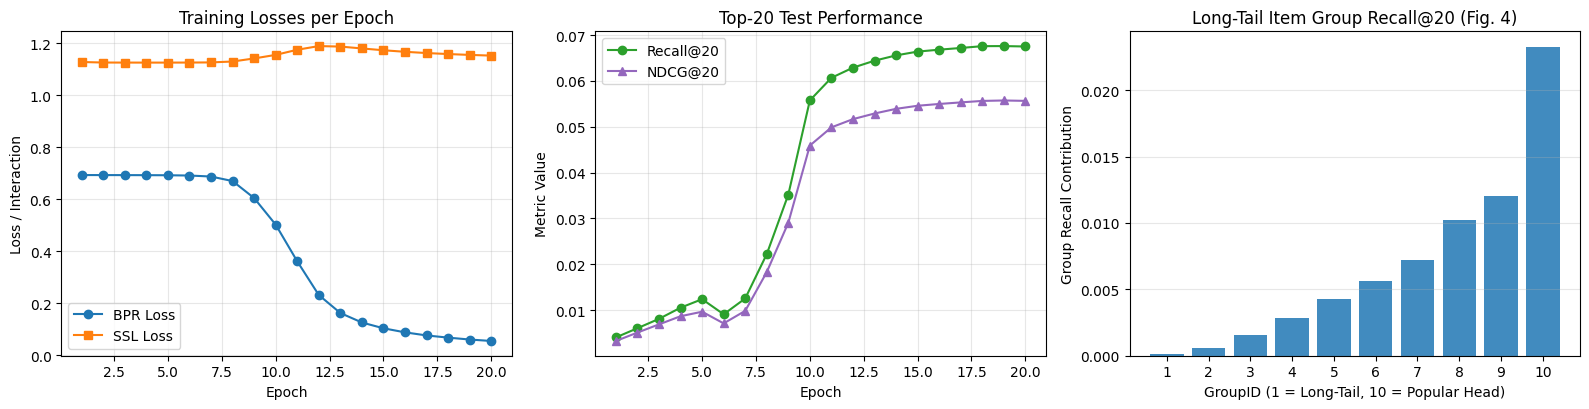

In [7]:
# ==============================================================================
# 5. Hyperparameter Configuration & End-to-End Training / Evaluation Runner
# ==============================================================================

@dataclass
class SGLConfig:
    # Dataset settings (use 'synthetic' for quick run, or 'yelp2018' / 'amazon-book' / 'ifashion')
    data_dir: str = "./dataset/yelp2018"
    dataset: str = "yelp2018"
    seed: int = 2021

    # SGL & LightGCN Hyperparameters (matching conf/SGL.ini)
    aug_type: str = "ED"            # 'ND': Node Dropout, 'ED': Edge Dropout, 'RW': Random Walk
    embed_size: int = 64            # Embedding dimension d
    n_layers: int = 3               # Number of LightGCN layers L
    reg: float = 1e-4               # L2 regularization weight lambda_2
    ssl_reg: float = 0.1            # SSL loss weight lambda_1
    ssl_ratio: float = 0.1          # Graph dropout ratio rho
    ssl_temp: float = 0.2           # InfoNCE softmax temperature tau
    ssl_mode: str = "both_side"     # 'user_side', 'item_side', or 'both_side'

    # Optimization & Evaluation settings
    lr: float = 0.001               # Learning rate for Adam optimizer
    batch_size: int = 2048          # Training batch size B
    epochs: int = 30                # Number of training epochs (set to 1000 for full benchmarks)
    verbose: int = 1                # Evaluate every `verbose` epochs
    stop_cnt: int = 10              # Early stopping patience
    top_k: list[int] = field(default_factory=lambda: [20])
    test_batch_size: int = 128
    start_testing_epoch: int = 0
    param_init: str = "xavier_uniform"


def run_sgl_pipeline(cfg: SGLConfig):
    """Runs the complete SGL preprocessing, training, evaluation, and plotting pipeline."""
    set_seed(cfg.seed)
    ssl_aug_type = cfg.aug_type.lower()

    print("=" * 80)
    print("Self-Supervised Graph Learning (SGL) for Recommendation (SIGIR '21)")
    print("=" * 80)
    print(
        f"[Config] dataset={cfg.dataset} | aug_type={cfg.aug_type.upper()} | "
        f"n_layers={cfg.n_layers} | embed_size={cfg.embed_size} | lr={cfg.lr} | "
        f"batch_size={cfg.batch_size}"
    )
    print(
        f"[SSL]    ssl_reg(lambda_1)={cfg.ssl_reg} | ssl_temp(tau)={cfg.ssl_temp} | "
        f"ssl_ratio(rho)={cfg.ssl_ratio} | ssl_mode={cfg.ssl_mode} | reg(lambda_2)={cfg.reg}"
    )
    print(f"[Device] Using {DEVICE}")

    # 1. Load dataset & construct intact normalized graph G
    dataset = SGLDataset(
        data_dir=cfg.data_dir,
        dataset_name=cfg.dataset,
        ssl_ratio=cfg.ssl_ratio,
        device=DEVICE,
    )
    print(
        f"[Data]   #Users: {dataset.num_users} | #Items: {dataset.num_items} | "
        f"#Train Interactions: {dataset.num_ratings}"
    )

    data_iter = PairwiseSampler(dataset, batch_size=cfg.batch_size, shuffle=True)
    evaluator = Evaluator(
        user_train_dict=dataset.train_user_dict,
        user_test_dict=dataset.test_user_dict,
        metrics=["Precision", "Recall", "NDCG"],
        top_k=cfg.top_k,
        batch_size=cfg.test_batch_size,
    )

    # 2. Initialize SGLModel & Adam optimizer
    model = SGLModel(
        num_users=dataset.num_users,
        num_items=dataset.num_items,
        norm_adj=dataset.norm_adj,
        embed_dim=cfg.embed_size,
        n_layers=cfg.n_layers,
        ssl_temp=cfg.ssl_temp,
        ssl_reg=cfg.ssl_reg,
        reg=cfg.reg,
        ssl_mode=cfg.ssl_mode,
        param_init=cfg.param_init,
    ).to(DEVICE)

    optimizer = torch.optim.Adam(model.lightgcn.parameters(), lr=cfg.lr)

    print("-" * 80)
    print("Metrics:\t" + evaluator.metrics_info())
    print("-" * 80)

    best_epoch = 0
    best_result = np.zeros(3 * len(cfg.top_k), dtype=np.float64)
    best_state_dict = None
    stopping_step = 0

    history = {"epoch": [], "bpr_loss": [], "ssl_loss": [], "recall": [], "ndcg": []}

    # 3. Training & Evaluation Loop
    for epoch in range(1, cfg.epochs + 1):
        total_loss, total_bpr_loss, total_reg_loss = 0.0, 0.0, 0.0
        t0 = time()

        # Construct two augmented views s_1(G), s_2(G) for this epoch
        sub_graph1, sub_graph2 = dataset.sample_subgraphs(
            aug_type=ssl_aug_type, n_layers=cfg.n_layers
        )

        model.train()
        for bat_users, bat_pos_items, bat_neg_items in data_iter:
            bat_users = torch.from_numpy(bat_users).long().to(DEVICE)
            bat_pos_items = torch.from_numpy(bat_pos_items).long().to(DEVICE)
            bat_neg_items = torch.from_numpy(bat_neg_items).long().to(DEVICE)

            loss, bpr_l, ssl_l, reg_l = model.calculate_loss(
                sub_graph1=sub_graph1,
                sub_graph2=sub_graph2,
                bat_users=bat_users,
                bat_pos_items=bat_pos_items,
                bat_neg_items=bat_neg_items,
            )

            total_loss += loss.item()
            total_bpr_loss += bpr_l.item()
            total_reg_loss += reg_l.item()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        avg_total = total_loss / dataset.num_ratings
        avg_bpr = total_bpr_loss / dataset.num_ratings
        avg_ssl = (total_loss - total_bpr_loss - total_reg_loss) / dataset.num_ratings
        avg_reg = total_reg_loss / dataset.num_ratings

        print(
            f"[iter {epoch:2d} : loss : {avg_total:.4f} = {avg_bpr:.4f} (BPR) + "
            f"{avg_ssl:.4f} (SSL) + {avg_reg:.4f} (Reg), time: {time() - t0:.2f}s]"
        )

        if epoch % cfg.verbose == 0 and epoch > cfg.start_testing_epoch:
            current_result, buf = evaluator.evaluate(model)
            print(f"epoch {epoch:2d}:\t{buf}")

            history["epoch"].append(epoch)
            history["bpr_loss"].append(avg_bpr)
            history["ssl_loss"].append(avg_ssl)
            history["recall"].append(current_result[1])
            history["ndcg"].append(current_result[2])

            if best_result[1] < current_result[1]:
                best_result = current_result
                best_epoch = epoch
                stopping_step = 0
                best_state_dict = {
                    k: v.cpu().clone() for k, v in model.lightgcn.state_dict().items()
                }
            else:
                stopping_step += 1
                if stopping_step >= cfg.stop_cnt:
                    print(f"Early stopping triggered at epoch: {epoch}")
                    break

    # 4. Restore best model & compute Long-Tail Group Recall (Section 4.3.1)
    if best_state_dict is not None:
        model.lightgcn.load_state_dict({k: v.to(DEVICE) for k, v in best_state_dict.items()})

    group_recalls = evaluator.evaluate_long_tail_groups(
        model=model,
        train_items=dataset.train_items,
        num_items=dataset.num_items,
        num_groups=10,
        k=cfg.top_k[0],
    )

    print("=" * 80)
    print(f"Best Result @ Epoch {best_epoch}:")
    print("Metrics:\t" + evaluator.metrics_info())
    print("Values: \t" + "\t".join([("%.8f" % x).ljust(12) for x in best_result]))
    print("-" * 80)
    group_str = " | ".join([f"G{g+1}: {val:.4f}" for g, val in enumerate(group_recalls)])
    print(f"Long-Tail Group Recall@{cfg.top_k[0]}: {group_str}")
    print("=" * 80)

    # 5. Plot Training Curves (Figure 5 style) & Long-Tail Group Recall (Figure 4 style)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

    axes[0].plot(history["epoch"], history["bpr_loss"], marker="o", label="BPR Loss")
    axes[0].plot(history["epoch"], history["ssl_loss"], marker="s", label="SSL Loss")
    axes[0].set_title("Training Losses per Epoch")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss / Interaction")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history["epoch"], history["recall"], marker="o", color="tab:green", label=f"Recall@{cfg.top_k[0]}")
    axes[1].plot(history["epoch"], history["ndcg"], marker="^", color="tab:purple", label=f"NDCG@{cfg.top_k[0]}")
    axes[1].set_title(f"Top-{cfg.top_k[0]} Test Performance")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Metric Value")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    axes[2].bar(np.arange(1, 11), group_recalls, color="tab:blue", alpha=0.85)
    axes[2].set_title(f"Long-Tail Item Group Recall@{cfg.top_k[0]} (Fig. 4)")
    axes[2].set_xlabel("GroupID (1 = Long-Tail, 10 = Popular Head)")
    axes[2].set_ylabel("Group Recall Contribution")
    axes[2].set_xticks(np.arange(1, 11))
    axes[2].grid(True, axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

    return model, history, group_recalls


# Execute the pipeline
config = SGLConfig(
    aug_type="ED",      # Choose 'ND', 'ED', or 'RW'
    n_layers=3,
    ssl_reg=0.1,
    ssl_temp=0.2,
    ssl_ratio=0.1,
    epochs=20,
)
trained_model, training_history, long_tail_recalls = run_sgl_pipeline(config)